In [24]:
import sys
from pathlib import Path

print("Python executable:", sys.executable)
print("Python version:", sys.version)

project_root = Path.cwd()
print("Notebook directory:", project_root)

import mido
import torch

print("Mido version:", mido.version_info)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python executable: /home/deep/projects/.venv-transkun/bin/python
Python version: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]
Notebook directory: /home/deep/projects/piano2midi/notebooks
Mido version: 1.3.3
PyTorch version: 2.9.1+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [25]:

from pathlib import Path
import wave
import mido

# Test audio and prediction generated earlier by Transkun
test_dir = Path.home() / "projects" / "piano2midi-test"
audio_path = test_dir / "piano_sample_20s.wav"
prediction_path = test_dir / "piano_sample_20s.mid"

# Ground-truth MIDI stored in the Windows project folder
reference_path = Path(
    "/mnt/c/Users/Deep/Desktop/Deep/Piano2MIDI/"
    "piano2midi/data/raw/maestro/piano_sample.midi"
)

for path in [audio_path, prediction_path, reference_path]:
    print(f"{path.name}: {'FOUND' if path.exists() else 'MISSING'}")

if audio_path.exists():
    with wave.open(str(audio_path), "rb") as audio:
        frames = audio.getnframes()
        sample_rate = audio.getframerate()

        print("\nAUDIO")
        print("Sample rate:", sample_rate, "Hz")
        print("Channels:", audio.getnchannels())
        print("Duration:", round(frames / sample_rate, 3), "seconds")

def inspect_midi(path):
    midi = mido.MidiFile(path)
    note_ons = sum(
        1
        for track in midi.tracks
        for msg in track
        if msg.type == "note_on" and msg.velocity > 0
    )
    tempos = [
        msg.tempo
        for track in midi.tracks
        for msg in track
        if msg.type == "set_tempo"
    ]

    print(f"\n{path.name}")
    print("Ticks per beat:", midi.ticks_per_beat)
    print("Tracks:", len(midi.tracks))
    print("Note-on events:", note_ons)
    print("Tempo events:", len(tempos))
    print(
        "Tempo values (BPM):",
        sorted({round(60_000_000 / tempo, 2) for tempo in tempos})
    )

if prediction_path.exists():
    inspect_midi(prediction_path)

if reference_path.exists():
    inspect_midi(reference_path)


piano_sample_20s.wav: FOUND
piano_sample_20s.mid: FOUND
piano_sample.midi: FOUND

AUDIO
Sample rate: 44100 Hz
Channels: 1
Duration: 20.0 seconds

piano_sample_20s.mid
Ticks per beat: 960
Tracks: 2
Note-on events: 95
Tempo events: 1
Tempo values (BPM): [120.0]

piano_sample.midi
Ticks per beat: 384
Tracks: 2
Note-on events: 17876
Tempo events: 1
Tempo values (BPM): [120.0]


In [26]:

from collections import defaultdict
import mido

def midi_notes_with_times(path):
    """Extract MIDI notes and convert their event times to seconds."""
    midi = mido.MidiFile(path)
    events = []

    for track_index, track in enumerate(midi.tracks):
        tick = 0
        for message in track:
            tick += message.time
            events.append((tick, track_index, message))

    # Sort events globally by tick while preserving track ordering at ties.
    events.sort(key=lambda item: (item[0], item[1]))

    tempo = 500_000
    previous_tick = 0
    elapsed = 0.0
    active = defaultdict(list)
    notes = []

    for tick, _, message in events:
        elapsed += (
            (tick - previous_tick)
            * tempo
            / 1_000_000
            / midi.ticks_per_beat
        )
        previous_tick = tick

        if message.type == "set_tempo":
            tempo = message.tempo

        elif message.type == "note_on" and message.velocity > 0:
            active[(message.channel, message.note)].append(elapsed)

        elif message.type == "note_off" or (
            message.type == "note_on" and message.velocity == 0
        ):
            key = (message.channel, message.note)
            if active[key]:
                onset = active[key].pop(0)
                if onset < 20:
                    notes.append({
                        "pitch": message.note,
                        "onset": onset,
                        "offset": elapsed,
                    })

    return notes

reference_notes = midi_notes_with_times(reference_path)
predicted_notes = midi_notes_with_times(prediction_path)

# Restrict the reference to notes beginning in the 20-second excerpt.
reference_notes = [
    n for n in reference_notes if n["onset"] < 20.0
]

print("Reference notes in excerpt:", len(reference_notes))
print("Predicted notes:", len(predicted_notes))

Reference notes in excerpt: 97
Predicted notes: 95


In [27]:

import sys
from pathlib import Path

# Import the evaluator from our project source.
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root / "src"))

from piano2midi.evaluation.metrics import evaluate_notes, notes_match

onset_tolerance = 0.05
offset_tolerance = 0.05

# Reproduce the official project score.
results = evaluate_notes(
    reference_notes,
    predicted_notes,
    onset_tolerance=onset_tolerance,
    offset_tolerance=offset_tolerance,
)

print("Benchmark results")
for key, value in results.items():
    print(f"{key}: {value:.4f}" if isinstance(value, float) else f"{key}: {value}")

# Identify the individual matches using the same greedy matching strategy.
matched_pairs = []
matched_reference_indices = set()
matched_prediction_indices = set()

for pred_idx, pred in enumerate(predicted_notes):
    for ref_idx, ref in enumerate(reference_notes):
        if ref_idx in matched_reference_indices:
            continue

        if notes_match(
            ref, pred,
            onset_tolerance=onset_tolerance,
            offset_tolerance=offset_tolerance,
        ):
            matched_pairs.append((ref_idx, pred_idx))
            matched_reference_indices.add(ref_idx)
            matched_prediction_indices.add(pred_idx)
            break

print("\nMatched pairs:", len(matched_pairs))

onset_errors = [
    predicted_notes[p]["onset"] - reference_notes[r]["onset"]
    for r, p in matched_pairs
]
offset_errors = [
    predicted_notes[p]["offset"] - reference_notes[r]["offset"]
    for r, p in matched_pairs
]

if onset_errors:
    print(f"Mean absolute onset error: {sum(abs(e) for e in onset_errors) / len(onset_errors):.4f} s")
    print(f"Mean absolute offset error: {sum(abs(e) for e in offset_errors) / len(offset_errors):.4f} s")
    print(f"Mean signed onset error: {sum(onset_errors) / len(onset_errors):+.4f} s")
    print(f"Mean signed offset error: {sum(offset_errors) / len(offset_errors):+.4f} s")


Benchmark results
TP: 76
FP: 19
FN: 21
precision: 0.8000
recall: 0.7835
F1: 0.7917

Matched pairs: 76
Mean absolute onset error: 0.0034 s
Mean absolute offset error: 0.0181 s
Mean signed onset error: -0.0011 s
Mean signed offset error: -0.0004 s


In [28]:

def nearest_same_pitch(note, candidates):
    """Find the closest candidate with the same pitch, by onset time."""
    same_pitch = [
        other for other in candidates
        if other["pitch"] == note["pitch"]
    ]

    if not same_pitch:
        return None

    return min(
        same_pitch,
        key=lambda other: abs(other["onset"] - note["onset"])
    )


unmatched_reference = [
    note for i, note in enumerate(reference_notes)
    if i not in matched_reference_indices
]

unmatched_predictions = [
    note for i, note in enumerate(predicted_notes)
    if i not in matched_prediction_indices
]

print("UNMATCHED REFERENCE NOTES (missed by the model)")
for note in unmatched_reference[:10]:
    nearest = nearest_same_pitch(note, predicted_notes)

    if nearest is None:
        print(
            f"Pitch {note['pitch']}, onset {note['onset']:.3f}s: "
            "no prediction of this pitch"
        )
    else:
        onset_error = nearest["onset"] - note["onset"]
        offset_error = nearest["offset"] - note["offset"]
        print(
            f"Pitch {note['pitch']}, onset {note['onset']:.3f}s | "
            f"nearest same-pitch prediction: onset error "
            f"{onset_error:+.3f}s, offset error {offset_error:+.3f}s"
        )

print("\nUNMATCHED PREDICTIONS (extra or mistimed)")
for note in unmatched_predictions[:10]:
    nearest = nearest_same_pitch(note, reference_notes)

    if nearest is None:
        print(
            f"Pitch {note['pitch']}, onset {note['onset']:.3f}s: "
            "no reference note of this pitch"
        )
    else:
        onset_error = nearest["onset"] - note["onset"]
        offset_error = nearest["offset"] - note["offset"]
        print(
            f"Pitch {note['pitch']}, onset {note['onset']:.3f}s | "
            f"nearest same-pitch reference: onset difference "
            f"{onset_error:+.3f}s, offset difference {offset_error:+.3f}s"
        )


UNMATCHED REFERENCE NOTES (missed by the model)
Pitch 42, onset 1.049s | nearest same-pitch prediction: onset error +0.002s, offset error +0.869s
Pitch 57, onset 3.492s | nearest same-pitch prediction: onset error +0.004s, offset error +0.052s
Pitch 61, onset 3.621s | nearest same-pitch prediction: onset error +0.005s, offset error -0.065s
Pitch 57, onset 5.805s | nearest same-pitch prediction: onset error +0.004s, offset error +0.070s
Pitch 50, onset 7.206s | nearest same-pitch prediction: onset error -0.004s, offset error +0.215s
Pitch 62, onset 6.079s | nearest same-pitch prediction: onset error -0.003s, offset error -0.051s
Pitch 59, onset 8.077s | nearest same-pitch prediction: onset error -0.008s, offset error -0.066s
Pitch 42, onset 8.247s | nearest same-pitch prediction: onset error -0.011s, offset error +0.375s
Pitch 42, onset 9.535s | nearest same-pitch prediction: onset error -0.002s, offset error -0.327s
Pitch 49, onset 9.750s | nearest same-pitch prediction: onset error +0

In [29]:

# Diagnostic: match notes by pitch and onset, ignoring offset.
# Each reference note can be matched only once.

onset_matched = []
used_reference = set()

for pred_idx, pred in enumerate(predicted_notes):
    candidates = [
        (ref_idx, ref)
        for ref_idx, ref in enumerate(reference_notes)
        if ref_idx not in used_reference
        and ref["pitch"] == pred["pitch"]
        and abs(ref["onset"] - pred["onset"]) <= 0.05
    ]

    if candidates:
        ref_idx, ref = min(
            candidates,
            key=lambda pair: abs(pair[1]["onset"] - pred["onset"])
        )
        used_reference.add(ref_idx)
        onset_matched.append((ref, pred))

duration_errors = [
    pred["offset"] - ref["offset"]
    for ref, pred in onset_matched
]

print("Matched by pitch + onset:", len(onset_matched))
print("Of these, also within 50 ms offset tolerance:",
      sum(abs(e) <= 0.05 for e in duration_errors))
print("Offset mismatches:", sum(abs(e) > 0.05 for e in duration_errors))

if duration_errors:
    print(
        "Mean absolute duration-end error:",
        round(sum(abs(e) for e in duration_errors) / len(duration_errors), 4),
        "seconds"
    )
    print(
        "Median signed end-time error:",
        round(sorted(duration_errors)[len(duration_errors) // 2], 4),
        "seconds"
    )

print("\nLargest end-time mismatches:")
for ref, pred in sorted(
    onset_matched,
    key=lambda pair: abs(pair[1]["offset"] - pair[0]["offset"]),
    reverse=True
)[:10]:
    print(
        f"Pitch {ref['pitch']}: "
        f"reference {ref['onset']:.3f}-{ref['offset']:.3f}s | "
        f"prediction {pred['onset']:.3f}-{pred['offset']:.3f}s | "
        f"end error {pred['offset'] - ref['offset']:+.3f}s"
    )


Matched by pitch + onset: 95
Of these, also within 50 ms offset tolerance: 76
Offset mismatches: 19
Mean absolute duration-end error: 0.1051 seconds
Median signed end-time error: -0.0023 seconds

Largest end-time mismatches:
Pitch 54: reference 10.423-10.895s | prediction 10.419-12.386s | end error +1.492s
Pitch 57: reference 8.221-10.402s | prediction 8.215-8.928s | end error -1.475s
Pitch 69: reference 18.415-20.215s | prediction 18.418-18.866s | end error -1.349s
Pitch 59: reference 19.290-19.411s | prediction 19.285-20.444s | end error +1.033s
Pitch 42: reference 1.049-1.717s | prediction 1.052-2.586s | end error +0.869s
Pitch 42: reference 8.247-8.715s | prediction 8.236-9.090s | end error +0.375s
Pitch 61: reference 16.858-20.335s | prediction 16.864-19.979s | end error -0.355s
Pitch 42: reference 9.535-10.113s | prediction 9.533-9.786s | end error -0.327s
Pitch 65: reference 16.078-16.522s | prediction 16.080-16.776s | end error +0.253s
Pitch 50: reference 7.206-7.388s | predict

In [30]:

def inspect_pedal_and_notes(path, label):
    midi = mido.MidiFile(path)
    pedal_events = []
    note_off_count = 0

    for track_index, track in enumerate(midi.tracks):
        tick = 0
        for msg in track:
            tick += msg.time

            if msg.type == "control_change" and msg.control == 64:
                pedal_events.append({
                    "track": track_index,
                    "tick": tick,
                    "value": msg.value,
                })

            if msg.type == "note_off" or (
                msg.type == "note_on" and msg.velocity == 0
            ):
                note_off_count += 1

    print(f"\n{label}")
    print("Note-off events:", note_off_count)
    print("Sustain pedal events (CC64):", len(pedal_events))
    print("First 12 pedal events:")
    for event in pedal_events[:12]:
        print(event)


inspect_pedal_and_notes(reference_path, "REFERENCE MIDI")
inspect_pedal_and_notes(prediction_path, "TRANSKUN PREDICTION")


REFERENCE MIDI
Note-off events: 17876
Sustain pedal events (CC64): 27874
First 12 pedal events:
{'track': 1, 'tick': 909, 'value': 37}
{'track': 1, 'tick': 924, 'value': 50}
{'track': 1, 'tick': 939, 'value': 58}
{'track': 1, 'tick': 955, 'value': 62}
{'track': 1, 'tick': 970, 'value': 65}
{'track': 1, 'tick': 986, 'value': 68}
{'track': 1, 'tick': 1001, 'value': 73}
{'track': 1, 'tick': 1016, 'value': 80}
{'track': 1, 'tick': 1031, 'value': 90}
{'track': 1, 'tick': 1046, 'value': 105}
{'track': 1, 'tick': 1061, 'value': 127}
{'track': 1, 'tick': 2949, 'value': 102}

TRANSKUN PREDICTION
Note-off events: 95
Sustain pedal events (CC64): 20
First 12 pedal events:
{'track': 1, 'tick': 2384, 'value': 127}
{'track': 1, 'tick': 7474, 'value': 0}
{'track': 1, 'tick': 7957, 'value': 127}
{'track': 1, 'tick': 11878, 'value': 0}
{'track': 1, 'tick': 12458, 'value': 127}
{'track': 1, 'tick': 16017, 'value': 0}
{'track': 1, 'tick': 16651, 'value': 127}
{'track': 1, 'tick': 20223, 'value': 0}
{'tra

In [31]:

from piano2midi.evaluation.metrics import evaluate_notes

offset_tolerances = [0.01, 0.025, 0.05, 0.075, 0.10, 0.20, 0.50]

print(
    f"{'Offset tol.':>12} {'TP':>5} {'FP':>5} {'FN':>5} "
    f"{'Precision':>10} {'Recall':>8} {'F1':>8}"
)
print("-" * 62)

for tolerance in offset_tolerances:
    result = evaluate_notes(
        reference_notes,
        predicted_notes,
        onset_tolerance=0.05,
        offset_tolerance=tolerance,
    )

    print(
        f"{tolerance * 1000:>9.0f} ms "
        f"{result['TP']:>5} "
        f"{result['FP']:>5} "
        f"{result['FN']:>5} "
        f"{result['precision']:>10.4f} "
        f"{result['recall']:>8.4f} "
        f"{result['F1']:>8.4f}"
    )


 Offset tol.    TP    FP    FN  Precision   Recall       F1
--------------------------------------------------------------
       10 ms    22    73    75     0.2316   0.2268   0.2292
       25 ms    57    38    40     0.6000   0.5876   0.5938
       50 ms    76    19    21     0.8000   0.7835   0.7917
       75 ms    81    14    16     0.8526   0.8351   0.8438
      100 ms    82    13    15     0.8632   0.8454   0.8542
      200 ms    84    11    13     0.8842   0.8660   0.8750
      500 ms    90     5     7     0.9474   0.9278   0.9375


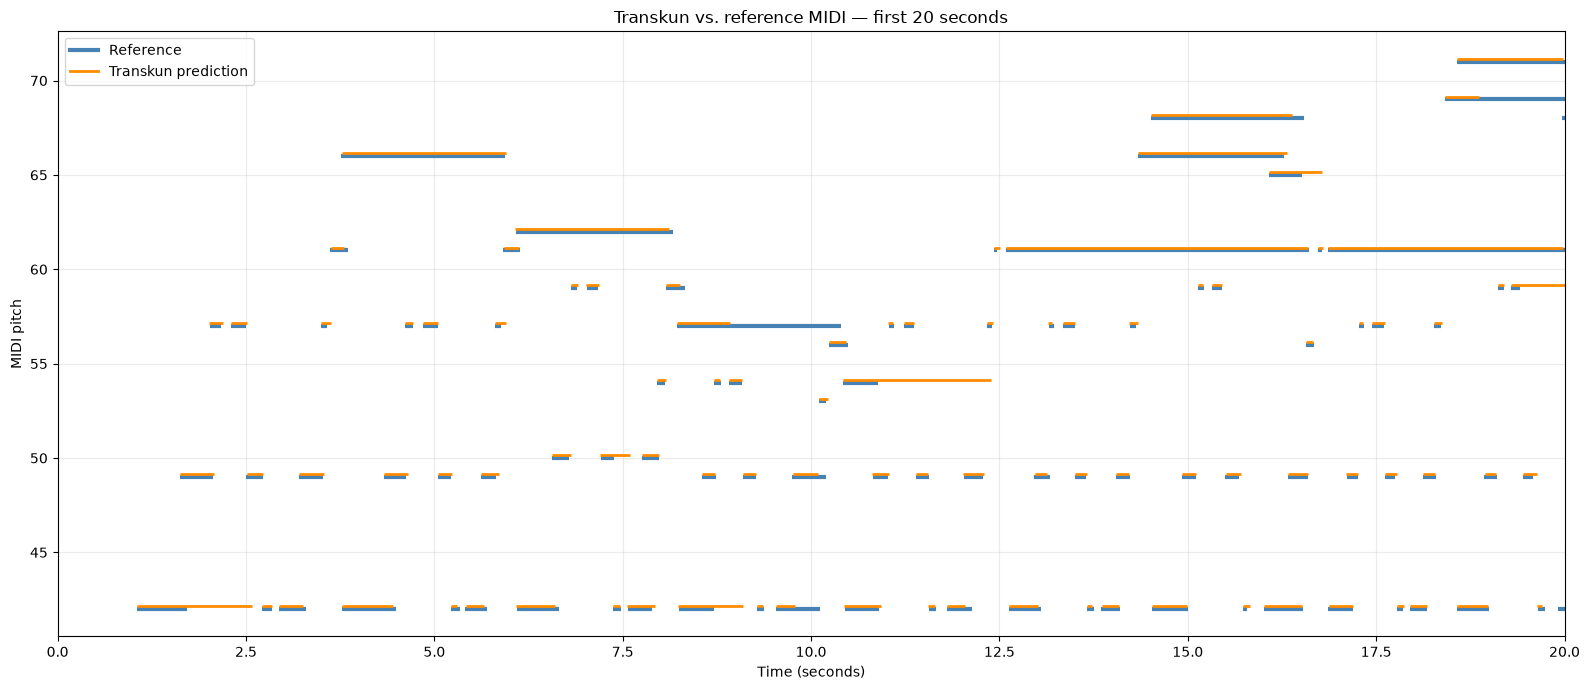

In [32]:

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(16, 7))

# Reference notes: blue horizontal bars
for note in reference_notes:
    ax.plot(
        [note["onset"], note["offset"]],
        [note["pitch"], note["pitch"]],
        color="steelblue",
        linewidth=3,
        solid_capstyle="butt",
    )

# Predicted notes: orange horizontal bars
for note in predicted_notes:
    ax.plot(
        [note["onset"], note["offset"]],
        [note["pitch"] + 0.15, note["pitch"] + 0.15],
        color="darkorange",
        linewidth=2,
        solid_capstyle="butt",
    )

ax.set_xlim(0, 20)
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("MIDI pitch")
ax.set_title("Transkun vs. reference MIDI — first 20 seconds")
ax.grid(True, alpha=0.25)

legend = [
    Line2D([0], [0], color="steelblue", lw=3, label="Reference"),
    Line2D([0], [0], color="darkorange", lw=2, label="Transkun prediction"),
]
ax.legend(handles=legend)
plt.tight_layout()
plt.show()

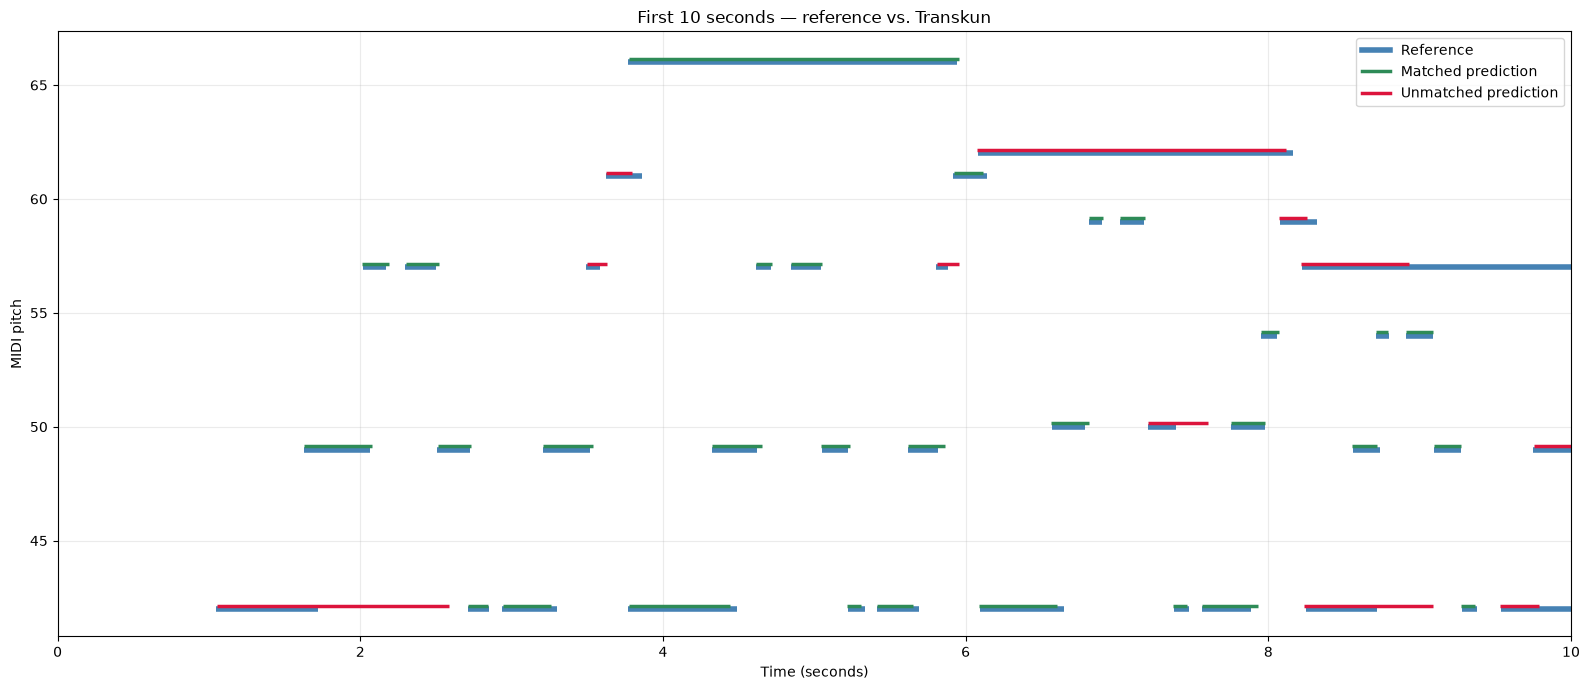

In [33]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(16, 7))

# Reference notes
for note in reference_notes:
    if note["onset"] >= 10:
        continue

    ax.plot(
        [note["onset"], note["offset"]],
        [note["pitch"], note["pitch"]],
        color="steelblue",
        linewidth=4,
        solid_capstyle="butt",
    )

# Predictions: green if matched, red if unmatched
for idx, note in enumerate(predicted_notes):
    if note["onset"] >= 10:
        continue

    color = (
        "seagreen"
        if idx in matched_prediction_indices
        else "crimson"
    )

    ax.plot(
        [note["onset"], note["offset"]],
        [note["pitch"] + 0.15, note["pitch"] + 0.15],
        color=color,
        linewidth=2.5,
        solid_capstyle="butt",
    )

ax.set_xlim(0, 10)
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("MIDI pitch")
ax.set_title("First 10 seconds — reference vs. Transkun")
ax.grid(True, alpha=0.25)
ax.legend(handles=[
    plt.Line2D([0], [0], color="steelblue", lw=4, label="Reference"),
    plt.Line2D([0], [0], color="seagreen", lw=2.5, label="Matched prediction"),
    plt.Line2D([0], [0], color="crimson", lw=2.5, label="Unmatched prediction"),
])
plt.tight_layout()
plt.show()


In [34]:

import mido
from pathlib import Path

reference_path = Path(
    "/mnt/c/Users/Deep/Desktop/Deep/Piano2MIDI/"
    "piano2midi/data/raw/maestro/piano_sample.midi"
)

reference_midi = mido.MidiFile(reference_path)

print("Reference duration:", round(reference_midi.length, 2), "seconds")
print("Ticks per beat:", reference_midi.ticks_per_beat)
print("Tracks:", len(reference_midi.tracks))


Reference duration: 1797.42 seconds
Ticks per beat: 384
Tracks: 2


In [35]:

from pathlib import Path
import shutil
import subprocess
import sys

source_audio = Path(
    "/mnt/c/Users/Deep/Desktop/Deep/Piano2MIDI/"
    "piano2midi/data/raw/maestro/piano_sample.mp3"
)

test_dir = Path.home() / "projects" / "piano2midi-test"
ffmpeg_path = shutil.which("ffmpeg")

print("Source audio exists:", source_audio.exists())
print("FFmpeg available:", ffmpeg_path is not None)
print("Test directory:", test_dir)
print("Transkun Python:", sys.executable)

assert source_audio.exists(), "Source MP3 not found"
assert ffmpeg_path is not None, "FFmpeg not found"

# Extract two distinct 20-second excerpts.
for start in [60, 120]:
    wav_path = test_dir / f"piano_sample_{start}s.wav"

    command = [
        ffmpeg_path,
        "-y",
        "-ss", str(start),
        "-i", str(source_audio),
        "-t", "20",
        "-vn",
        "-ac", "1",
        "-ar", "44100",
        str(wav_path),
    ]

    subprocess.run(command, check=True, capture_output=True, text=True)
    print(f"Created: {wav_path} ({wav_path.stat().st_size:,} bytes)")


Source audio exists: True
FFmpeg available: True
Test directory: /home/deep/projects/piano2midi-test
Transkun Python: /home/deep/projects/.venv-transkun/bin/python
Created: /home/deep/projects/piano2midi-test/piano_sample_60s.wav (1,764,078 bytes)
Created: /home/deep/projects/piano2midi-test/piano_sample_120s.wav (1,764,078 bytes)


In [36]:

import subprocess
import time

transkun_executable = Path.home() / "projects" / ".venv-transkun" / "bin" / "transkun"

assert transkun_executable.exists(), f"Transkun not found: {transkun_executable}"

for start in [60, 120]:
    wav_path = test_dir / f"piano_sample_{start}s.wav"
    midi_path = test_dir / f"piano_sample_{start}s.mid"

    command = [
        str(transkun_executable),
        str(wav_path),
        str(midi_path),
        "--device", "cuda",
    ]

    print(f"\nTranscribing excerpt starting at {start}s...")
    print("Command:", " ".join(command))

    start_time = time.perf_counter()
    result = subprocess.run(command, capture_output=True, text=True)
    elapsed = time.perf_counter() - start_time

    if result.returncode != 0:
        print(result.stdout)
        print(result.stderr)
        raise RuntimeError(f"Transkun failed on the {start}s excerpt")

    print(f"Completed in {elapsed:.2f} seconds")
    print(f"Output: {midi_path}")
    print(f"Output size: {midi_path.stat().st_size:,} bytes")



Transcribing excerpt starting at 60s...
Command: /home/deep/projects/.venv-transkun/bin/transkun /home/deep/projects/piano2midi-test/piano_sample_60s.wav /home/deep/projects/piano2midi-test/piano_sample_60s.mid --device cuda
Completed in 12.48 seconds
Output: /home/deep/projects/piano2midi-test/piano_sample_60s.mid
Output size: 1,102 bytes

Transcribing excerpt starting at 120s...
Command: /home/deep/projects/.venv-transkun/bin/transkun /home/deep/projects/piano2midi-test/piano_sample_120s.wav /home/deep/projects/piano2midi-test/piano_sample_120s.mid --device cuda
Completed in 7.77 seconds
Output: /home/deep/projects/piano2midi-test/piano_sample_120s.mid
Output size: 1,078 bytes


In [37]:

from collections import defaultdict
import mido

def midi_notes_full(path):
    """Extract all notes from a MIDI file, in seconds, without time filtering."""
    midi = mido.MidiFile(path)
    events = []

    for track_index, track in enumerate(midi.tracks):
        tick = 0
        for message in track:
            tick += message.time
            events.append((tick, track_index, message))

    events.sort(key=lambda item: (item[0], item[1]))

    tempo = 500_000
    previous_tick = 0
    elapsed = 0.0
    active = defaultdict(list)
    notes = []

    for tick, _, message in events:
        elapsed += (
            (tick - previous_tick)
            * tempo
            / 1_000_000
            / midi.ticks_per_beat
        )
        previous_tick = tick

        if message.type == "set_tempo":
            tempo = message.tempo

        elif message.type == "note_on" and message.velocity > 0:
            active[(message.channel, message.note)].append(elapsed)

        elif message.type == "note_off" or (
            message.type == "note_on" and message.velocity == 0
        ):
            key = (message.channel, message.note)
            if active[key]:
                onset = active[key].pop(0)
                notes.append({
                    "pitch": message.note,
                    "onset": onset,
                    "offset": elapsed,
                })

    return notes


full_reference_notes = midi_notes_full(reference_path)

print("Total reference notes:", len(full_reference_notes))
print(
    "Reference time range:",
    round(min(n["onset"] for n in full_reference_notes), 2),
    "to",
    round(max(n["offset"] for n in full_reference_notes), 2),
    "seconds",
)


Total reference notes: 17876
Reference time range: 1.05 to 1793.24 seconds


In [38]:

from piano2midi.evaluation.metrics import evaluate_notes

for start in [60, 120]:
    prediction_path = test_dir / f"piano_sample_{start}s.mid"

    # Select reference notes from this excerpt and shift them to local time.
    reference_window = notes_in_window(full_reference_notes, start)

    # Prediction already starts at time zero.
    prediction_window = midi_notes_full(prediction_path)

    result = evaluate_notes(
        reference_window,
        prediction_window,
        onset_tolerance=0.05,
        offset_tolerance=0.05,
    )

    print(f"\nExcerpt: {start}-{start + 20}s")
    print(f"Reference notes: {len(reference_window)}")
    print(f"Predicted notes: {len(prediction_window)}")

    for key, value in result.items():
        if isinstance(value, float):
            print(f"{key}: {value:.4f}")
        else:
            print(f"{key}: {value}")



Excerpt: 60-80s
Reference notes: 130
Predicted notes: 132
TP: 72
FP: 60
FN: 58
precision: 0.5455
recall: 0.5538
F1: 0.5496

Excerpt: 120-140s
Reference notes: 130
Predicted notes: 125
TP: 101
FP: 24
FN: 29
precision: 0.8080
recall: 0.7769
F1: 0.7922


In [39]:
print("Full reference notes:", len(full_reference_notes))
print("Reference notes at 60–80s:", len(notes_in_window(full_reference_notes, 60)))
print("Reference notes at 120–140s:", len(notes_in_window(full_reference_notes, 120)))

print("\nFirst reference note in each window:")
for start in [60, 120]:
    window = notes_in_window(full_reference_notes, start)
    print(start, window[:3])

Full reference notes: 17876
Reference notes at 60–80s: 130
Reference notes at 120–140s: 130

First reference note in each window:
60 [{'pitch': 59, 'onset': 0.07812500000005684, 'offset': 0.33203125000006395}, {'pitch': 73, 'onset': 0.18098958333339255, 'offset': 0.39192708333339965}, {'pitch': 53, 'onset': 0.36718750000006395, 'offset': 0.5065104166667354}]
120 [{'pitch': 44, 'onset': 4.638020833332831, 'offset': 4.675781249999503}, {'pitch': 37, 'onset': 4.889322916666174, 'offset': 4.933593749999503}, {'pitch': 44, 'onset': 5.132812499999503, 'offset': 5.171874999999503}]


In [46]:
# Rebuild the full reference list using the unrestricted parser.
full_reference_notes = midi_notes_full(reference_path)

print("Full reference notes:", len(full_reference_notes))
print("Notes at 60–80s:", len(notes_in_window(full_reference_notes, 60)))
print("Notes at 120–140s:", len(notes_in_window(full_reference_notes, 120)))


Full reference notes: 17876
Notes at 60–80s: 130
Notes at 120–140s: 130


In [45]:

def match_by_pitch_and_onset(reference, predictions, tolerance=0.05):
    """Greedy one-to-one matching, ignoring note offsets."""
    used_reference = set()
    pairs = []

    for pred_idx, pred in enumerate(predictions):
        candidates = [
            (ref_idx, ref)
            for ref_idx, ref in enumerate(reference)
            if ref_idx not in used_reference
            and ref["pitch"] == pred["pitch"]
            and abs(ref["onset"] - pred["onset"]) <= tolerance
        ]

        if candidates:
            ref_idx, ref = min(
                candidates,
                key=lambda pair: abs(pair[1]["onset"] - pred["onset"])
            )
            used_reference.add(ref_idx)
            pairs.append((ref_idx, pred_idx))

    return pairs

def notes_in_window(notes, start, duration=20.0):
    end = start + duration

    return [
        {
            "pitch": note["pitch"],
            "onset": note["onset"] - start,
            "offset": note["offset"] - start,
        }
        for note in notes
        if start <= note["onset"] < end
    ]


for start in [0, 60, 120]:
    reference_window = notes_in_window(full_reference_notes, start)
    prediction_path = (
    test_dir / "piano_sample_20s.mid"
    if start == 0
    else test_dir / f"piano_sample_{start}s.mid"
)
    prediction_window = midi_notes_full(prediction_path)

    pairs = match_by_pitch_and_onset(
        reference_window,
        prediction_window,
        tolerance=0.05,
    )

    matched = len(pairs)
    precision = matched / len(prediction_window) if prediction_window else 0
    recall = matched / len(reference_window) if reference_window else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    print(f"\nExcerpt: {start}-{start + 20}s")
    print(f"Pitch + onset matches: {matched}")
    print(f"Unmatched predictions: {len(prediction_window) - matched}")
    print(f"Unmatched reference notes: {len(reference_window) - matched}")
    print(f"Pitch + onset F1: {f1:.4f}")



Excerpt: 0-20s
Pitch + onset matches: 95
Unmatched predictions: 0
Unmatched reference notes: 2
Pitch + onset F1: 0.9896

Excerpt: 60-80s
Pitch + onset matches: 128
Unmatched predictions: 4
Unmatched reference notes: 2
Pitch + onset F1: 0.9771

Excerpt: 120-140s
Pitch + onset matches: 125
Unmatched predictions: 0
Unmatched reference notes: 5
Pitch + onset F1: 0.9804


In [47]:
print("Function exists:", "notes_in_window" in globals())

if "notes_in_window" in globals():
    print("Function object:", notes_in_window)
    print("Defined in module:", notes_in_window.__module__)
    print("Function source:")
    import inspect
    print(inspect.getsource(notes_in_window))

Function exists: True
Function object: <function notes_in_window at 0x71a8ac7237e0>
Defined in module: __main__
Function source:
def notes_in_window(notes, start, duration=20.0):
    end = start + duration

    return [
        {
            "pitch": note["pitch"],
            "onset": note["onset"] - start,
            "offset": note["offset"] - start,
        }
        for note in notes
        if start <= note["onset"] < end
    ]



In [48]:

from pathlib import Path

from piano2midi.transcription.transkun_backend import transcribe

test_dir = Path.home() / "projects" / "piano2midi-test"
transkun_executable = (
    Path.home() / "projects" / ".venv-transkun" / "bin" / "transkun"
)

audio_path = test_dir / "piano_sample_20s.wav"
output_path = test_dir / "piano_sample_20s_integrated.mid"

result_path = transcribe(
    audio_path,
    output_path,
    device="cuda",
    executable=transkun_executable,
)

print("Transcription completed!")
print("Output:", result_path)
print("File size:", f"{result_path.stat().st_size:,} bytes")


Transcription completed!
Output: /home/deep/projects/piano2midi-test/piano_sample_20s_integrated.mid
File size: 835 bytes


In [49]:

import mido

original_path = test_dir / "piano_sample_20s.mid"
integrated_path = test_dir / "piano_sample_20s_integrated.mid"

original = mido.MidiFile(original_path)
integrated = mido.MidiFile(integrated_path)

def midi_summary(midi):
    return {
        "ticks_per_beat": midi.ticks_per_beat,
        "tracks": len(midi.tracks),
        "note_on_events": sum(
            msg.type == "note_on" and msg.velocity > 0
            for track in midi.tracks
            for msg in track
        ),
        "note_off_events": sum(
            msg.type == "note_off"
            or (msg.type == "note_on" and msg.velocity == 0)
            for track in midi.tracks
            for msg in track
        ),
    }

original_summary = midi_summary(original)
integrated_summary = midi_summary(integrated)

print("Original:", original_summary)
print("Integrated:", integrated_summary)
print("Summaries identical:", original_summary == integrated_summary)


Original: {'ticks_per_beat': 960, 'tracks': 2, 'note_on_events': 95, 'note_off_events': 95}
Integrated: {'ticks_per_beat': 960, 'tracks': 2, 'note_on_events': 95, 'note_off_events': 95}
Summaries identical: True


In [50]:

original_notes = midi_notes_full(original_path)
integrated_notes = midi_notes_full(integrated_path)

def normalize_notes(notes):
    return sorted(
        (
            note["pitch"],
            round(note["onset"], 6),
            round(note["offset"], 6),
        )
        for note in notes
    )

original_normalized = normalize_notes(original_notes)
integrated_normalized = normalize_notes(integrated_notes)

print("Original note count:", len(original_normalized))
print("Integrated note count:", len(integrated_normalized))
print("All note events identical:", original_normalized == integrated_normalized)

if original_normalized != integrated_normalized:
    for index, (original, integrated) in enumerate(
        zip(original_normalized, integrated_normalized)
    ):
        if original != integrated:
            print("First mismatch:", index)
            print("Original:", original)
            print("Integrated:", integrated)
            break


Original note count: 95
Integrated note count: 95
All note events identical: True
